### DermAI Diagnostics — Predictive Modelling



- Logistic Regression
- Random Forest 
- XGBoost

- Performance is compared using:

- Accuracy
-         
- Recall
- F1-score
- ROC-AUC                   



### STEP 1 - Import Relevant Libraries

In [37]:
import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import sklearn
import seaborn as sns
 

warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from xgboost import XGBClassifier



In [38]:
# Set Project Paths

PROCESSED_DIR = os.path.join("..", "data", "processed")
MODELS_DIR = os.path.join("..", "Models")
REPORTS_DIR = os.path.join("..", "reports")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

### STEP 2 — Load Training and Testing Data

In [39]:

X_train = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_train.csv")
)

X_test = pd.read_csv(
    os.path.join(PROCESSED_DIR, "X_test.csv")
)

y_train = (
    pd.read_csv(
        os.path.join(PROCESSED_DIR, "y_train.csv")
    )
    .squeeze("columns")
)

y_test = (
    pd.read_csv(
        os.path.join(PROCESSED_DIR, "y_test.csv")
    )
    .squeeze("columns")
)

In [40]:
# step 2b: check shape
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)




X_train: (870, 24)
X_test : (218, 24)
y_train: (870,)
y_test : (218,)


In [41]:
# step 2c: Load the Preprocessor
preprocessor = joblib.load(
    os.path.join(MODELS_DIR, "preprocessor.joblib")
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [42]:
# step 2d: Check Class Balance
class_counts = y_train.value_counts().sort_index()

print(class_counts)

cancerous_flag
0    593
1    277
Name: count, dtype: int64


### STEP 3 - Logistic Regression

In [43]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        random_state=42,
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [44]:
# Train Logistic Regression

lr_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['age','age_group','gender',...,'changed','bleed','elevation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rema

In [45]:
# Logistic Regression Predictions
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Logistic Regression Evaluation
lr_results = pd.DataFrame({

    "Model": ["Logistic Regression"],

    "Accuracy": [
        accuracy_score(y_test, lr_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred)
    ],

    "Recall": [
        recall_score(y_test, lr_pred)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred)
    ],

    "ROC AUC": [
        roc_auc_score(y_test, lr_prob)
    ]

})

lr_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.885,0.789,0.87,0.828,0.955


In [46]:
# Step 3e — Classification Report
print(
    classification_report(
        y_test,
        lr_pred,
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Benign       0.94      0.89      0.91       149
   Malignant       0.79      0.87      0.83        69

    accuracy                           0.89       218
   macro avg       0.86      0.88      0.87       218
weighted avg       0.89      0.89      0.89       218



### STEP 4 — Random Forest Classifier

- Non-linear relationships
- Feature interactions
- Complex decision boundaries


In [47]:
# step 4a — Build and Train the Model
rf_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])
rf_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

In [48]:
# step 4b:  the Model
rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['age','age_group','gender',...,'changed','bleed','elevation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rema

In [49]:
# Step 4c — Make Predictions
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

In [50]:
# Step 4d — Evaluate Random Forest
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_rf, zero_division=0))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report")

print(
    classification_report(    
        y_test,
        y_pred_rf,  
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)



Accuracy : 0.8761467889908257
Precision: 0.7763157894736842
Recall   : 0.855072463768116
F1 Score : 0.8137931034482758
ROC AUC  : 0.9491294621145803

Classification Report
              precision    recall  f1-score   support

      Benign       0.93      0.89      0.91       149
   Malignant       0.78      0.86      0.81        69

    accuracy                           0.88       218
   macro avg       0.85      0.87      0.86       218
weighted avg       0.88      0.88      0.88       218



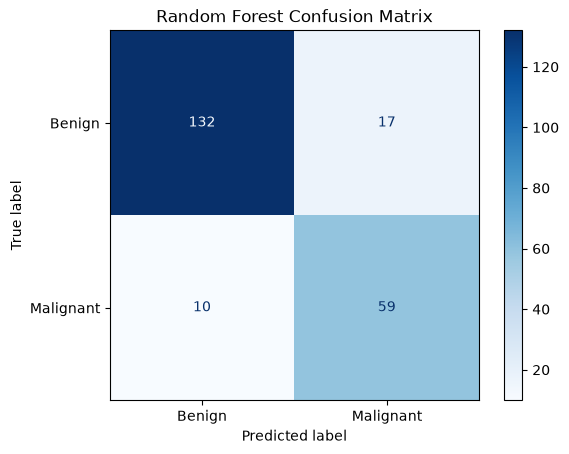

In [51]:
# Step 4e — Confusion Matrix
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()


### STEP 5 — XGBoost Classifier


In [52]:
# step 5a: calculate the class weight from the training target.

class_counts = y_train.value_counts().sort_index()

negative_count = class_counts.get(0, 0)
positive_count = class_counts.get(1, 0)

scale_pos_weight = negative_count / positive_count

print("Benign training cases   :", negative_count)
print("Malignant training cases:", positive_count)
print("Scale pos weight        :", round(scale_pos_weight, 3))

Benign training cases   : 593
Malignant training cases: 277
Scale pos weight        : 2.141


In [53]:
# step 5b: Build the Model
xgb_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", XGBClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",     
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

In [54]:
# step 5c: Train XGBoost
xgb_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['age','age_group','gender',...,'changed','bleed','elevation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all rema

In [55]:
# step 5d: Make Predictions
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [56]:
# Step 4d — Evaluate Xgboost
print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_xgb, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_xgb, zero_division=0))
print("ROC AUC  :", roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report")
print(
    classification_report(
        y_test,
        y_pred_xgb,
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)



Accuracy : 0.8853211009174312
Precision: 0.7972972972972973
Recall   : 0.855072463768116
F1 Score : 0.8251748251748252
ROC AUC  : 0.9479622604804979

Classification Report
              precision    recall  f1-score   support

      Benign       0.93      0.90      0.91       149
   Malignant       0.80      0.86      0.83        69

    accuracy                           0.89       218
   macro avg       0.86      0.88      0.87       218
weighted avg       0.89      0.89      0.89       218



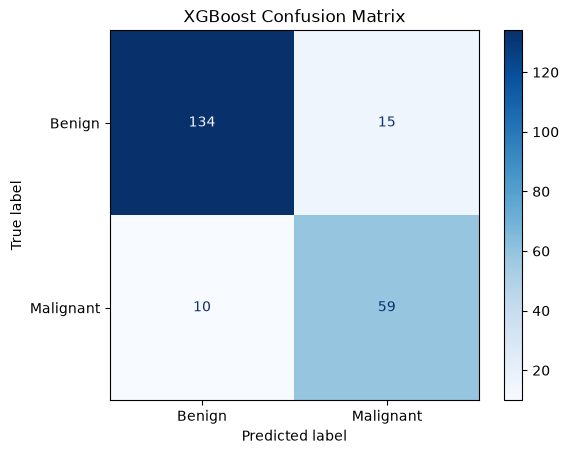

In [57]:
# step 5f: Confusion Matrix
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Benign", "Malignant"]
).plot(cmap="Blues")

plt.title("XGBoost Confusion Matrix")
plt.show()

### STEP 6 - Hyperparameter Tuning

In [58]:
# Hyperparameter Tuning

# The initial comparison showed that Logistic Regression achieved the highest performance. However, tree-based models often benefit from hyperparameter tuning.

# In this step, RandomizedSearchCV is used to optimise:

# Random Forest
# XGBoost

# The models are evaluated using **ROC AUC**, which is an appropriate metric for this healthcare classification problem because it measures the model's ability to distinguish between benign and malignant lesions across different classification thresholds.

# RandomizedSearchCV is selected instead of GridSearchCV because it explores a wide range of parameter combinations while significantly reducing computational time.

In [59]:
from sklearn.model_selection import RandomizedSearchCV

models = {
    "Random Forest": (
        rf_model,
        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__max_depth": [None, 10, 20],
            "classifier__min_samples_split": [2, 5],                 
            "classifier__min_samples_leaf": [1, 2]
        }
    ),

    "XGBoost": (
        xgb_model,
        {
            "classifier__n_estimators": [100, 200, 300],
            "classifier__learning_rate": [0.01, 0.05, 0.1],
            "classifier__max_depth": [3, 5, 7]
        }
    )
}

best_models = {}

for name, (pipeline, params) in models.items():

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=params,
        n_iter=10,
        cv=5,
        scoring="roc_auc",
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    print(f"\n{name}")
    print("Best Parameters:")
    print(search.best_params_)
    print(f"Best CV ROC AUC: {search.best_score_:.3f}")


Random Forest
Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 10}
Best CV ROC AUC: 0.974

XGBoost
Best Parameters:
{'classifier__n_estimators': 100, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}
Best CV ROC AUC: 0.974


In [60]:
# step 6b -  evaluate tuned models

tuned_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        "ROC AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })

tuned_results = pd.DataFrame(tuned_results)

tuned_results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,0.881,0.759,0.913,0.829,0.946
1,XGBoost,0.872,0.766,0.855,0.808,0.947


In [61]:
# step 6c - Combine Logistic Regression with tuned models

final_comparison = pd.concat(

    [lr_results, tuned_results],

    ignore_index=True

)

final_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.885,0.789,0.870,0.828,0.955
1,Random Forest,0.881,0.759,0.913,0.829,0.946
2,XGBoost,0.872,0.766,0.855,0.808,0.947


In [62]:
# step 6d: Rnak the models
model_ranking = final_comparison.sort_values(
    by="ROC AUC",
    ascending=False
).reset_index(drop=True)

model_ranking.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.885,0.789,0.870,0.828,0.955
1,XGBoost,0.872,0.766,0.855,0.808,0.947
2,Random Forest,0.881,0.759,0.913,0.829,0.946


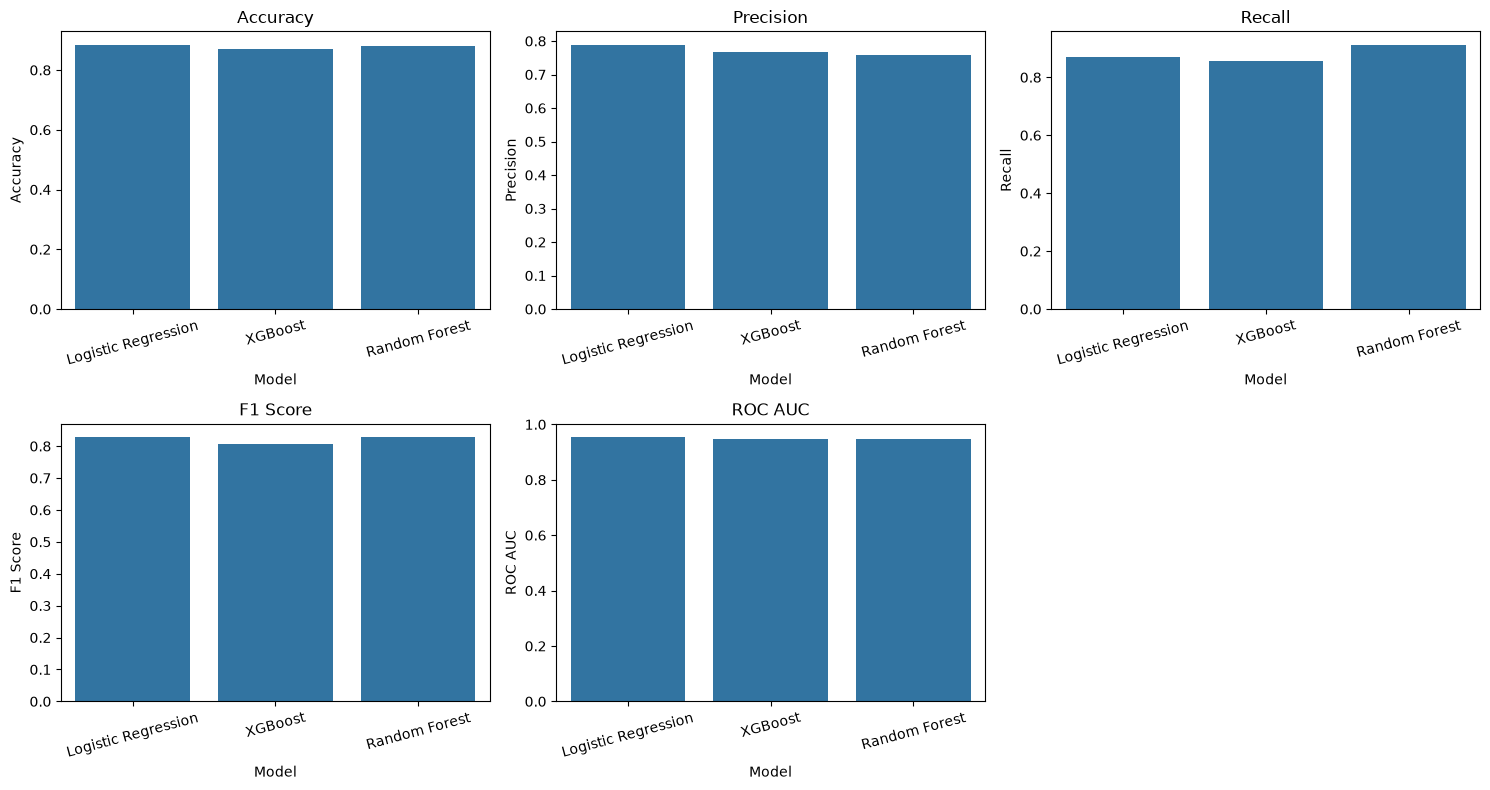

In [63]:
metrics = [

    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"

]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15,8)
)

axes = axes.flatten()

for ax, metric in zip(axes, metrics):

    sns.barplot(

        data=model_ranking,

        x="Model",

        y=metric,

        ax=ax

    )

    ax.set_title(metric)

    ax.tick_params(
        axis="x",
        rotation=15
    )

plt.delaxes(axes[-1])

plt.tight_layout()

plt.show()

In [64]:
# Step 6e — Identify the Initial Best Model
best_model_name = final_comparison.iloc[0]["Model"]

print(f"Best Model: {best_model_name}")

Best Model: Logistic Regression


In [66]:
### Model Comparison Summary

# final comparison shows the performance of all candidate models on the independent test dataset.

#  model with the highest ROC AUC was selected as the final model because it demonstrated the best ability to distinguish between benign and malignant lesions while maintaining strong recall and F1 score.

# selected model or feature importance analysis, explainability, API development, and deployment.

In [67]:
# step 6f - select best model
model_lookup = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = model_lookup[best_model_name]

print("Selected model:", best_model_name)

Selected model: Logistic Regression


### STEP 7 — SHAP Explainability

- Machine learning models often achieve high predictive performance but can be difficult to interpret.

- SHAP (SHapley Additive exPlanations) explains how each feature contributes to an individual prediction and the model as a whole.

- This improves transparency and supports trust in AI-assisted clinical decision-making.

In [69]:
# step 7a - Transform the test data
import shap

X_test_processed = best_model.named_steps["preprocessor"].transform(X_test)

# Get the trained Logistic Regression model
classifier = best_model.named_steps["classifier"]

# step 7b - Create SHAP explainer
explainer = shap.LinearExplainer(
    classifier,
    X_test_processed
)

# step 7c -  Calculate SHAP values
shap_values = explainer(X_test_processed)

Background dataset has 218 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=218 when initializing the masker.


In [70]:
# step 7d - get feature names
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

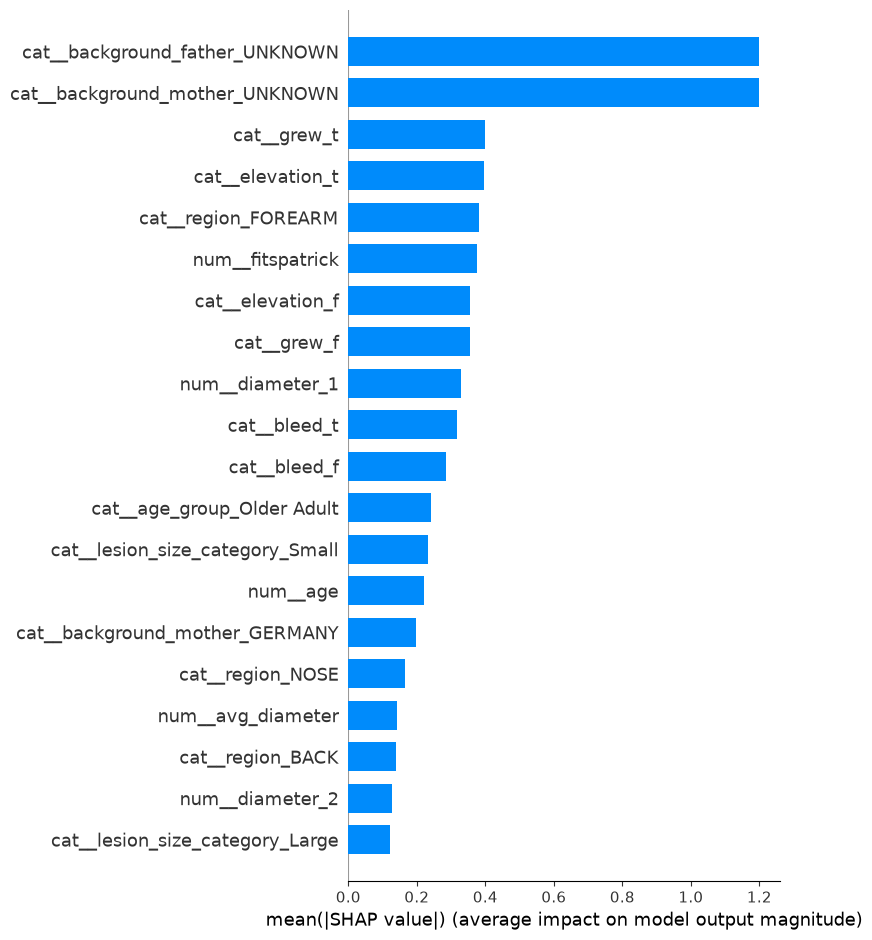

In [71]:
# step 7e - summary plot
shap.summary_plot(
    shap_values.values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar"
    
)

### STEP 8 - Select and Save the best model

In [72]:
# step 8a - Select the trained model

if best_model_name == "Logistic Regression":
    best_model = lr_model

elif best_model_name == "Random Forest":
    best_model = best_models["Random Forest"]

else:
    best_model = best_models["XGBoost"]

In [73]:
# step 8b - create the path

MODELS_DIR = os.path.join(
    "..",
    "Models"
)

REPORTS_DIR = os.path.join(
    "..",
    "reports"
)

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

In [74]:
# step 8c - save models

final_comparison.to_csv(
    os.path.join(
        REPORTS_DIR,
        "final_comparison.csv"
    ),
    index=False
)

joblib.dump(
    lr_model,
    os.path.join(
        MODELS_DIR,
        "logistic_regression_pipeline.joblib"
    )
)

joblib.dump(
    rf_model,
    os.path.join(
        MODELS_DIR,
        "random_forest_pipeline.joblib"
    )
)

joblib.dump(
    xgb_model,
    os.path.join(
        MODELS_DIR,
        "xgboost_pipeline.joblib"
    )
)

joblib.dump(
    best_model,
    os.path.join(
        MODELS_DIR,
        "best_model_pipeline.joblib"
    )
)

print("Models and comparison results saved successfully.")

Models and comparison results saved successfully.


In [75]:
# step 8d - Feature Importance


fitted_preprocessor = (
    lr_model
    .named_steps["preprocessor"]
)

feature_names = (
    fitted_preprocessor
    .get_feature_names_out()
)

xgb_importances = (
    xgb_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importances
})

In [76]:
feature_importance["Feature"] = (
    feature_importance["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

In [78]:
top20 = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
    .head(20)
)

top20

,Feature,Importance
35,background_father_UNKNOWN,0.292680
45,background_mother_UNKNOWN,0.181509
1,fitspatrick,0.041612
65,grew_f,0.027773
66,grew_t,0.026646
71,bleed_f,0.021938
74,elevation_t,0.017188
72,bleed_t,0.016359
2,diameter_1,0.016271
73,elevation_f,0.015928


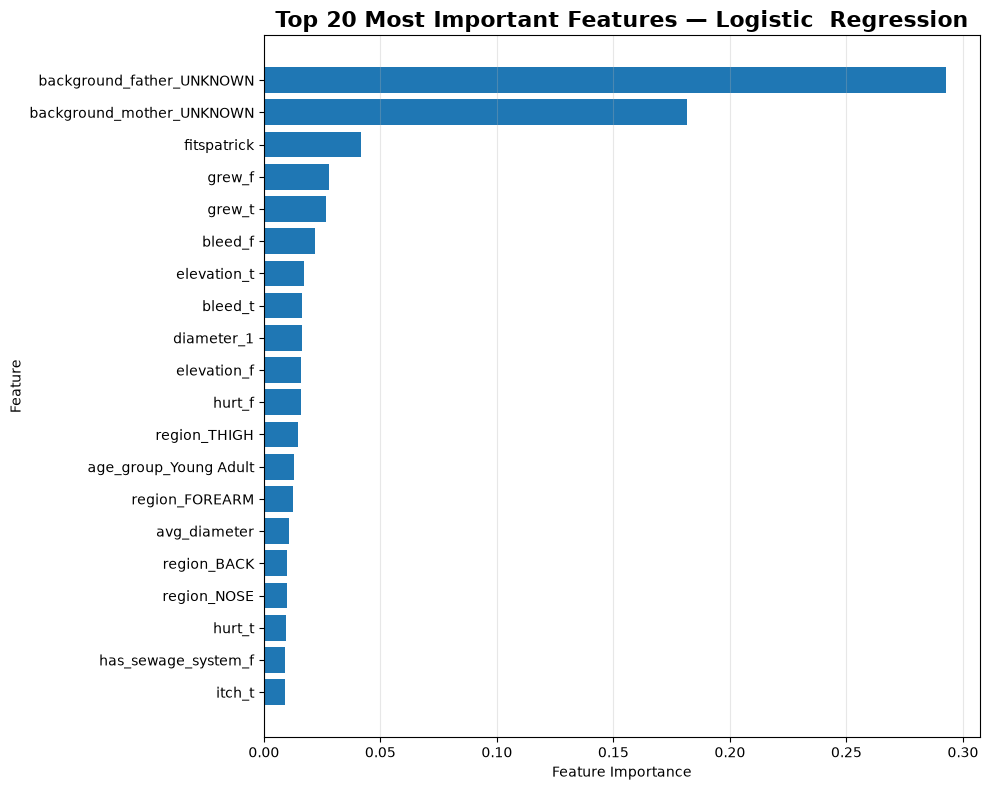

In [79]:
plt.figure(figsize=(10, 8))

plt.barh(
    top20["Feature"][::-1],
    top20["Importance"][::-1]
)

plt.title(
    "Top 20 Most Important Features — Logistic  Regression",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [80]:
# save the feature importance 
feature_importance.to_csv(
    os.path.join(
        REPORTS_DIR,
        "lr_feature_importance.csv"
    ),
    index=False
)